# EDA: цены Day-Ahead, Венгрия, 2024-2025

Сводный ноутбук команды 136 по чекпоинту 2. Собран из четырёх индивидуальных EDA в `eda/`
(Николаев, Щеблыкина, Писмаров, Велем): повторяющиеся части взяты один раз, разные дополняют друг друга.

Данные от куратора, в репозиторий не входят (лежат локально в `data/raw/`, см. `.gitignore`).
Часовой ряд 01.01.2024-31.12.2025, timestamp в UTC. Загрузка через `dayahead.data.load_raw`
переводит время в Europe/Budapest, дальше везде локальное время.

Колонки: цель `price_eur_mwh` (EUR/MWh) и шесть прогнозов на сутки вперёд, известных на момент прогноза:
спрос, солнце, ветер, атом, сальдо обмена с соседями (MWh, минус = импорт), температура (C).

Разделы: 1) данные и качество, 2) целевая переменная, 3) сезонность, 4) выбросы,
5) связи признаков с ценой, 6) лаги и стационарность, 7) выводы.

In [1]:
import warnings
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller

from dayahead.data import load_raw

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80  # чтобы ноутбук с выводом влезал в лимит pre-commit 1.5 МБ

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
DATA_PATH = ROOT / "data" / "raw" / "hu_dayahead_2024_2025.csv"
TARGET = "price_eur_mwh"
FEATURES = ["demand_forecast_mwh", "solar_forecast_mwh", "wind_forecast_mwh",
            "nuclear_forecast_mwh", "net_exchange_forecast_mwh", "temperature_forecast_c"]

df = load_raw(DATA_PATH)
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 17544 entries, 2024-01-01 00:00:00+01:00 to 2025-12-31 23:00:00+01:00
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   price_eur_mwh              17544 non-null  float64
 1   demand_forecast_mwh        17544 non-null  float64
 2   solar_forecast_mwh         17544 non-null  float64
 3   net_exchange_forecast_mwh  17544 non-null  float64
 4   wind_forecast_mwh          17544 non-null  float64
 5   nuclear_forecast_mwh       17544 non-null  float64
 6   temperature_forecast_c     17544 non-null  float64
dtypes: float64(7)
memory usage: 1.1 MB


## 1. Данные и качество

In [3]:
df.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
price_eur_mwh,17544.0,104.7,73.1,-210.0,72.8,97.7,126.4,999.0
demand_forecast_mwh,17544.0,4932.7,849.9,2303.4,4290.3,4860.8,5504.7,7442.8
solar_forecast_mwh,17544.0,709.5,1021.8,0.0,0.0,34.9,1266.2,4329.1
net_exchange_forecast_mwh,17544.0,-1096.1,1332.2,-5365.3,-2064.2,-1299.8,-219.2,3819.9
wind_forecast_mwh,17544.0,66.3,61.7,0.6,16.5,47.1,97.5,291.8
nuclear_forecast_mwh,17544.0,1740.1,222.6,1372.2,1440.0,1900.0,1900.0,1949.5
temperature_forecast_c,17544.0,12.6,9.4,-7.0,4.9,12.0,20.0,35.9


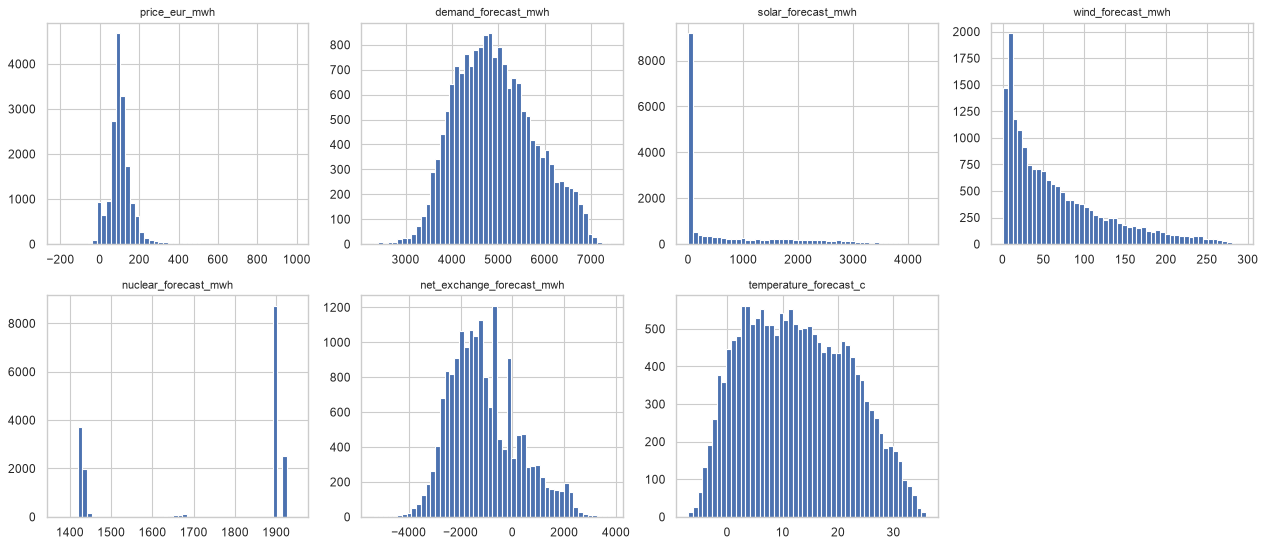

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), [TARGET] + FEATURES):
    ax.hist(df[col], bins=50)
    ax.set_title(col, fontsize=10)
axes[1, 3].axis("off")
plt.tight_layout()

Распределения признаков: у солнца огромный столбик в нуле (ночь), ветер скошен вправо и мал по величине
(в среднем 66 MWh, около 1% спроса), атом принимает несколько дискретных уровней (ремонты блоков),
спрос и температура близки к нормальному. Сальдо в основном отрицательное: Венгрия нетто-импортёр.

In [5]:
step = df.index.to_series().diff().dropna().dt.total_seconds()
print("пропусков:", int(df.isna().sum().sum()))
print("дубликатов времени:", df.index.duplicated().sum())
print("шаг ровно 1 ч во всех строках:", bool((step == 3600).all()))
print("строк:", len(df), "(ожидается 8784 + 8760 = 17544)")
print("часов в сутках:", df.groupby(df.index.date).size().value_counts().to_dict())

print("solar < 0:", (df["solar_forecast_mwh"] < 0).sum(),
      "| wind < 0:", (df["wind_forecast_mwh"] < 0).sum(),
      "| demand <= 0:", (df["demand_forecast_mwh"] <= 0).sum())
night = df.index.hour.isin([23, 0, 1, 2, 3])
print("максимум солнца ночью (23-3 ч):", df.loc[night, "solar_forecast_mwh"].max())

пропусков: 0
дубликатов времени: 0
шаг ровно 1 ч во всех строках: True
строк: 17544 (ожидается 8784 + 8760 = 17544)
часов в сутках: {24: 727, 23: 2, 25: 2}
solar < 0: 0 | wind < 0: 0 | demand <= 0: 0
максимум солнца ночью (23-3 ч): 0.0


Пропусков, дубликатов и дыр нет, шаг ровно час. Сутки с 23 и 25 часами это переход на летнее/зимнее время,
в локальном времени он учтён. Физически невозможных значений в прогнозах нет, солнце ночью ноль.

In [6]:
# сальдо обмена: доля значений, кратных 100 MWh, по месяцам
ne = df["net_exchange_forecast_mwh"]
round_share = (ne % 100 == 0).groupby([df.index.year, df.index.month]).mean().unstack()
round_share.round(2)

timestamp,1,2,3,4,5,6,7,8,9,10,11,12
timestamp,,,,,,,,,,,,
2024,0.07,0.13,0.15,0.17,0.29,0.57,0.71,0.76,0.39,0.00,0.0,0.0
2025,0.00,0.00,0.00,0.00,0.00,0.00,0.01,0.00,0.00,0.01,0.0,0.0


Единственная странность в данных: с апреля по сентябрь 2024 прогноз сальдо обмена в основном круглый
(в июле-августе до трёх четвертей значений кратны 100 MWh), с октября 2024 круглых значений нет.
Похоже, в источнике сменилась методика прогноза. На корреляции это почти не влияет, но для модели
признак в 2024 грубее, чем в 2025. Уточнить у куратора.

## 2. Целевая переменная

In [7]:
price = df[TARGET]
print(price.describe().round(1).to_dict())
print(f"часов с ценой <= 0: {(price <= 0).sum()} ({(price <= 0).mean():.1%}), "
      f"> 300: {(price > 300).sum()} ({(price > 300).mean():.1%})")
print("skew:", round(price.skew(), 2), "| skew после arcsinh(price / 50):",
      round(np.arcsinh(price / 50).skew(), 2))

{'count': 17544.0, 'mean': 104.7, 'std': 73.1, 'min': -210.0, '25%': 72.8, '50%': 97.7, '75%': 126.4, 'max': 999.0}
часов с ценой <= 0: 650 (3.7%), > 300: 311 (1.8%)
skew: 3.35 | skew после arcsinh(price / 50): -0.84


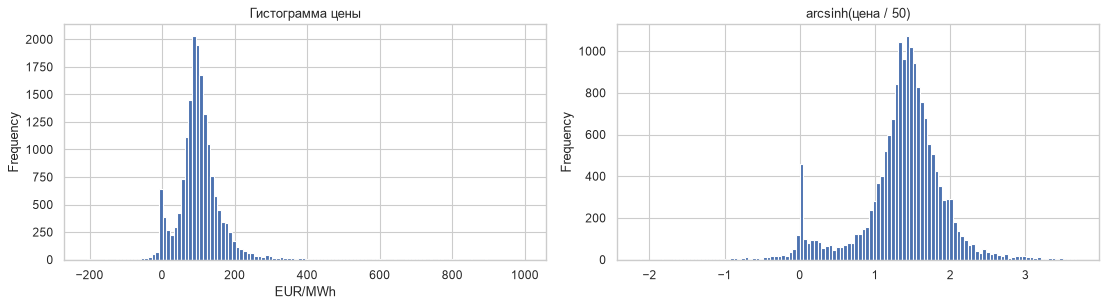

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
price.plot(kind="hist", bins=120, ax=axes[0], title="Гистограмма цены")
axes[0].set(xlabel="EUR/MWh")
np.arcsinh(price / 50).plot(kind="hist", bins=120, ax=axes[1], title="arcsinh(цена / 50)")
plt.tight_layout()

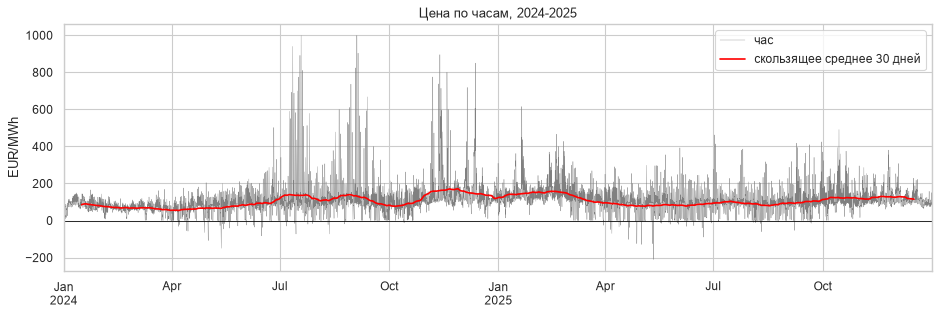

In [9]:
daily = price.resample("D").mean()
fig, ax = plt.subplots(figsize=(14, 4))
price.plot(ax=ax, lw=0.3, color="grey", label="час")
daily.rolling(30, center=True).mean().plot(ax=ax, color="red", label="скользящее среднее 30 дней")
ax.axhline(0, color="black", lw=0.7)
ax.set(title="Цена по часам, 2024-2025", xlabel="", ylabel="EUR/MWh")
ax.legend();

Медиана 98, среднее 105 EUR/MWh, диапазон от -210 до 999. Распределение сильно скошено вправо: коэффициент
асимметрии 3.3 (у симметричного распределения 0). Логарифм к цене не применить из-за отрицательных значений;
для сравнения справа показан arcsinh, который делает распределение почти симметричным.
Уровень и разброс меняются во времени: лето 2024 самое волатильное, 2025 в среднем дороже 2024
(108 против 101), но спокойнее.

## 3. Сезонность

In [10]:
eda = df.copy()
eda["hour"] = eda.index.hour
eda["dow"] = eda.index.dayofweek
eda["month"] = eda.index.month
eda["year"] = eda.index.year
eda["is_weekend"] = eda["dow"] >= 5
eda["season"] = eda["month"].map(lambda m: {12: "зима", 1: "зима", 2: "зима", 3: "весна", 4: "весна", 5: "весна",
                                            6: "лето", 7: "лето", 8: "лето"}.get(m, "осень"))
hu_holidays = holidays.HU(years=[2024, 2025])
eda["is_holiday"] = pd.Series(eda.index.date, index=eda.index).map(lambda d: d in hu_holidays)
eda["residual_load"] = (eda["demand_forecast_mwh"] - eda["solar_forecast_mwh"]
                        - eda["wind_forecast_mwh"] - eda["nuclear_forecast_mwh"])

### Суточный профиль

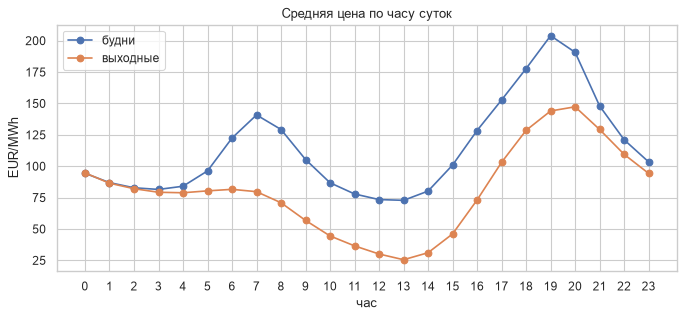

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))
for wk, label in [(False, "будни"), (True, "выходные")]:
    price[eda["is_weekend"] == wk].groupby(eda["hour"]).mean().plot(ax=ax, marker="o", label=label)
ax.set(title="Средняя цена по часу суток", xlabel="час", ylabel="EUR/MWh", xticks=range(24))
ax.legend();

Два пика: утренний около 7 ч и вечерний 18-20 ч, вечерний в полтора раза выше. Днём в 12-13 ч провал
ниже ночного уровня, это солнце. В выходные утреннего пика нет, дневной провал глубже, профиль
в среднем на 30 EUR/MWh ниже.

### Час x месяц

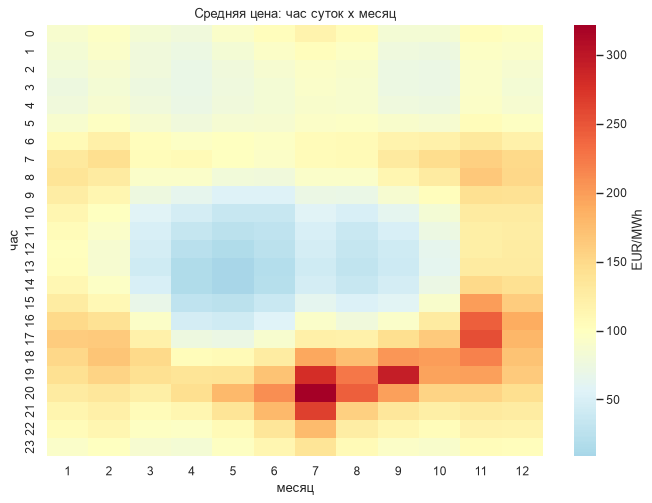

In [12]:
pivot = price.groupby([eda["hour"], eda["month"]]).mean().unstack()
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(pivot, cmap="RdYlBu_r", center=100, ax=ax, cbar_kws={"label": "EUR/MWh"})
ax.set(title="Средняя цена: час суток x месяц", xlabel="месяц", ylabel="час");

Дневной провал есть только с марта по сентябрь и углубляется к апрелю-маю. Зимой провала нет, выражены оба пика.
Самые дорогие часы: вечера ноября-декабря. Суточный профиль зависит от сезона, календарные признаки должны
работать в связке (час x месяц), а не по отдельности.

### Неделя, праздники, год

                   mean  median  count
будни             115.8   102.3  11928
выходной           80.6    87.3   4992
праздник в будни   85.0    89.2    624


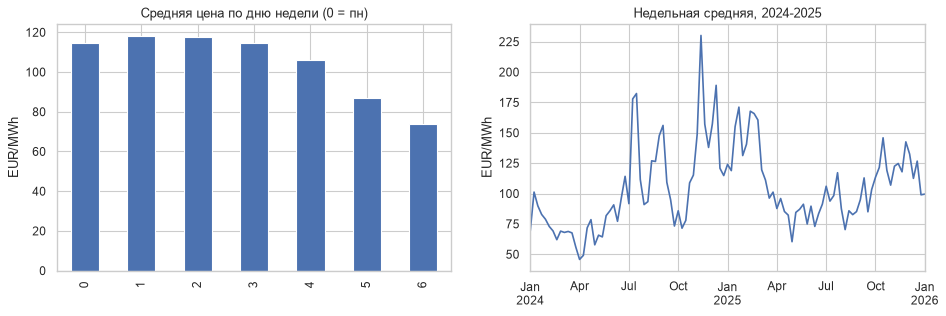

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
price.groupby(eda["dow"]).mean().plot(kind="bar", ax=axes[0], title="Средняя цена по дню недели (0 = пн)")
price.resample("W").mean().plot(ax=axes[1], title="Недельная средняя, 2024-2025")
axes[0].set(xlabel="", ylabel="EUR/MWh")
axes[1].set(xlabel="", ylabel="EUR/MWh");

kind = np.select([eda["is_weekend"], eda["is_holiday"]], ["выходной", "праздник в будни"], "будни")
print(price.groupby(kind).agg(["mean", "median", "count"]).round(1))

In [14]:
price.groupby([eda['year'], eda['month']]).mean().unstack(0).round(1)

year,2024,2025
month,,
1,85.7,140.2
2,69.4,158.9
3,65.1,109.0
4,62.0,85.5
5,72.2,80.9
6,91.7,84.1
7,135.5,102.6
8,120.8,80.5
9,106.1,101.9


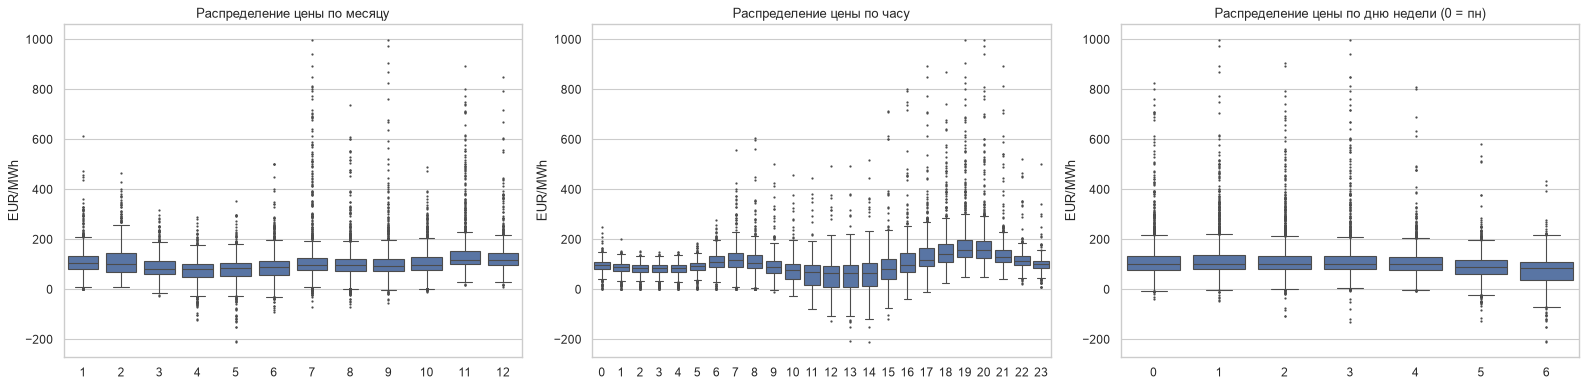

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
for ax, col, title in zip(axes, ["month", "hour", "dow"], ["по месяцу", "по часу", "по дню недели (0 = пн)"]):
    sns.boxplot(x=eda[col], y=price, ax=ax, fliersize=1, color="C0")
    ax.set(title=f"Распределение цены {title}", xlabel="", ylabel="EUR/MWh")
plt.tight_layout()

Boxplot показывают не только уровень, но и разброс: в июле, сентябре и ноябре самые длинные хвосты сверху,
с апреля по сентябрь хвосты вниз до отрицательных значений. По часам разброс максимален в 18-20 ч, минимален ночью;
воскресенье не только дешевле, но и стабильнее.

Воскресенье самый дешёвый день, суббота близко, пн-чт самые дорогие. Государственные праздники Венгрии в будни
(624 часа) по цене ведут себя как выходные: 85 против 116 EUR/MWh в обычные будни. Признак `is_holiday` нужен.

Годовой цикл: дорогие зима и июль, дешёвые апрель-май. Годы при этом не повторяют друг друга: зима 2024/25
вдвое дороже зимы 2024 (январь-февраль 140-159 против 70-86 EUR/MWh), а лето 2025 дешевле лета 2024.
Устойчивого тренда нет, есть смена уровня по сезонам, модели нужны лаги, а не номер дня.

### Автокорреляция

{1: np.float64(0.88), 12: np.float64(0.22), 24: np.float64(0.78), 48: np.float64(0.64), 168: np.float64(0.69), 336: np.float64(0.57)}


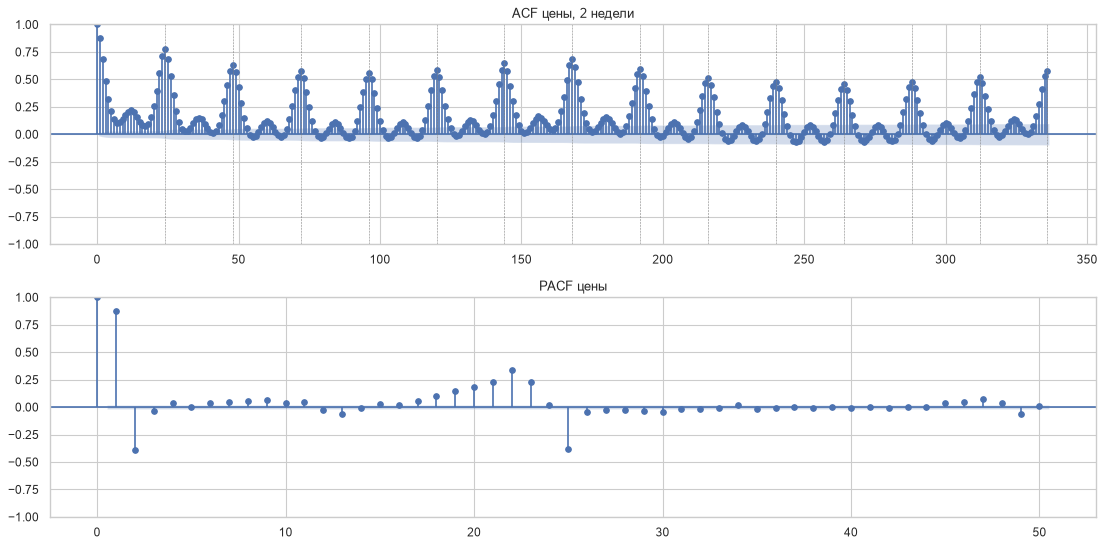

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_acf(price, lags=24 * 14, ax=axes[0], title="ACF цены, 2 недели")
plot_pacf(price, lags=50, ax=axes[1], title="PACF цены")
for k in range(24, 24 * 14 + 1, 24):
    axes[0].axvline(k, color="grey", lw=0.5, ls="--")
plt.tight_layout()
print({k: round(price.autocorr(k), 2) for k in [1, 12, 24, 48, 168, 336]})

Пики на кратных 24 ч, из дальних самый высокий на 168 ч (0.69 против 0.64 на 48 ч): недельная сезонность
сильнее, чем кажется по средним дням недели. PACF: сильный лаг 1 и отдельная группа лагов 20-24, остальное
близко к нулю. Для Day-Ahead лаг 1 недоступен (см. раздел 6), так что рабочие лаги это 24 и 168 ч.

## 4. Выбросы

IQR-границы: -7 ... 207, вне их 1050 часов (6.0%)


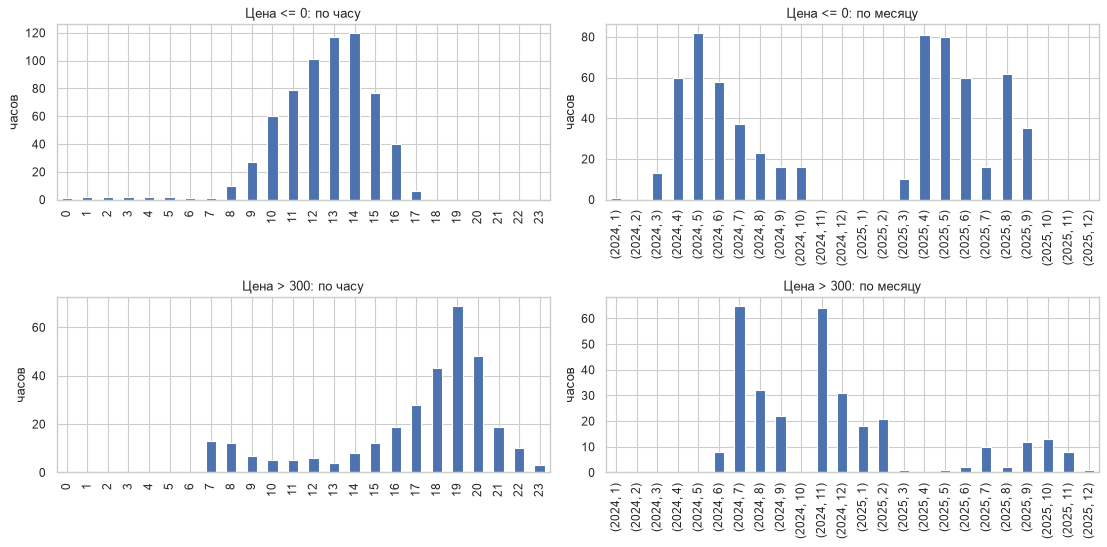

In [17]:
neg = price <= 0
peak = price > 300
q1, q3 = price.quantile([0.25, 0.75])
iqr_out = (price < q1 - 1.5 * (q3 - q1)) | (price > q3 + 1.5 * (q3 - q1))
print(f"IQR-границы: {q1 - 1.5 * (q3 - q1):.0f} ... {q3 + 1.5 * (q3 - q1):.0f}, "
      f"вне их {iqr_out.sum()} часов ({iqr_out.mean():.1%})")

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
neg.groupby(eda["hour"]).sum().plot(kind="bar", ax=axes[0, 0], title="Цена <= 0: по часу")
neg.groupby([eda["year"], eda["month"]]).sum().plot(kind="bar", ax=axes[0, 1], title="Цена <= 0: по месяцу")
peak.groupby(eda["hour"]).sum().plot(kind="bar", ax=axes[1, 0], title="Цена > 300: по часу")
peak.groupby([eda["year"], eda["month"]]).sum().plot(kind="bar", ax=axes[1, 1], title="Цена > 300: по месяцу")
for ax in axes.ravel():
    ax.set(xlabel="", ylabel="часов")
plt.tight_layout()

In [18]:
# чем отличаются часы с ценой <= 0 от обычных дневных часов (10-16), медианы признаков
day = eda[eda["hour"].between(10, 16)]
compare = pd.DataFrame({
    "цена <= 0": day.loc[day[TARGET] <= 0, FEATURES + ["residual_load"]].median(),
    "дневные часы, все": day[FEATURES + ["residual_load"]].median(),
}).round(0)
print("доля выходных и праздников среди часов с ценой <= 0:",
      round((eda.loc[neg, "is_weekend"] | eda.loc[neg, "is_holiday"]).mean(), 2))
compare

доля выходных и праздников среди часов с ценой <= 0: 0.86


,цена <= 0,"дневные часы, все"
demand_forecast_mwh,3758.0,4766.0
solar_forecast_mwh,2853.0,1856.0
wind_forecast_mwh,22.0,32.0
nuclear_forecast_mwh,1900.0,1900.0
net_exchange_forecast_mwh,1000.0,20.0
temperature_forecast_c,23.0,15.0
residual_load,-833.0,1076.0


In [19]:
# десять самых дорогих часов
cols = [TARGET, "demand_forecast_mwh", "solar_forecast_mwh", "nuclear_forecast_mwh",
        "net_exchange_forecast_mwh", "temperature_forecast_c", "residual_load"]
eda.sort_values(TARGET, ascending=False)[cols].head(10).round(0)

,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,net_exchange_forecast_mwh,temperature_forecast_c,residual_load
timestamp,,,,,,,
2024-07-18 20:00:00+02:00,999.0,6721.0,19.0,1900.0,-600.0,28.0,4724.0
2024-09-03 19:00:00+02:00,999.0,6539.0,15.0,1428.0,-200.0,27.0,5060.0
2024-09-03 20:00:00+02:00,975.0,6426.0,0.0,1428.0,-200.0,26.0,4950.0
2024-07-11 20:00:00+02:00,940.0,6571.0,20.0,1900.0,-600.0,31.0,4577.0
2024-09-04 19:00:00+02:00,903.0,6555.0,12.0,1428.0,-200.0,27.0,5066.0
2024-11-12 17:00:00+01:00,895.0,6768.0,0.0,1900.0,-4329.0,3.0,4862.0
2024-07-17 21:00:00+02:00,891.0,6467.0,0.0,1900.0,-600.0,26.0,4490.0
2024-09-03 18:00:00+02:00,868.0,6481.0,209.0,1428.0,-200.0,29.0,4823.0
2024-07-11 19:00:00+02:00,850.0,6617.0,191.0,1900.0,-600.0,33.0,4468.0


Отрицательные и нулевые цены: 650 часов (3.7%), почти все в 9-17 ч с апреля по сентябрь, более 80% в выходные
и праздники. В эти часы солнце вдвое выше обычного дневного, спрос ниже, остаточная нагрузка около нуля:
это солнечные полдни при низком спросе, а не ошибки данных.

В эти же часы Венгрия экспортирует: медиана сальдо +1000 MWh против нуля в обычные дневные часы.

Пики выше 300 EUR: 311 часов, в основном вечера 17-21 ч, сильно сгруппированы: июль и ноябрь 2024 дают почти
половину. Самые дорогие часы: вечер, спрос выше 6500 MWh, нулевое солнце, в сентябре 2024 ещё и остановлен
блок АЭС. Импорт при этом ниже обычного вечернего (медиана -1900 против -2300 MWh): дефицит закрывать нечем.
В 2025 пиков заметно меньше.

Обрезать нельзя, это целевые режимы рынка. Метрики считать отдельно по хвостам.

## 5. Связи признаков с ценой

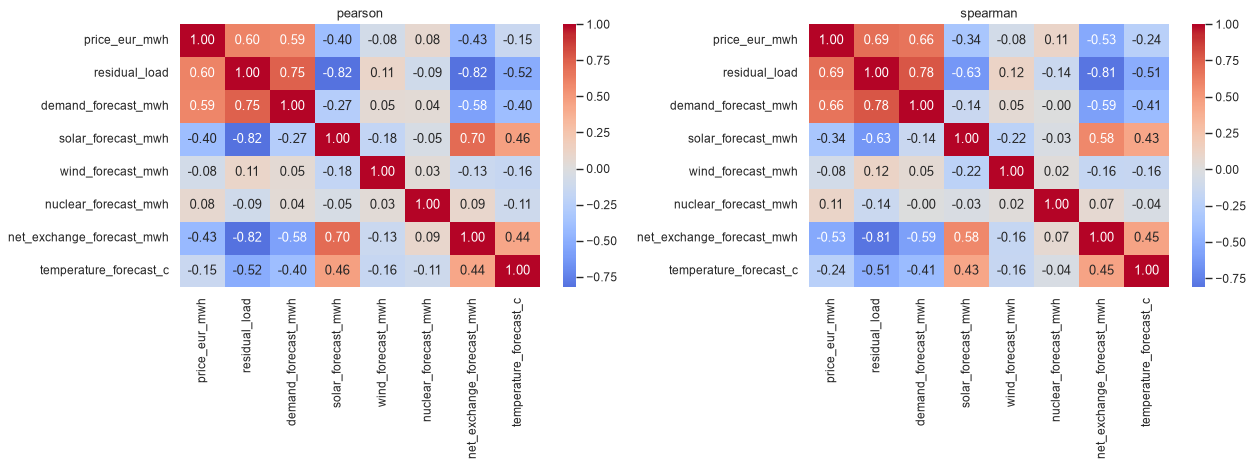

In [20]:
corr_cols = [TARGET, "residual_load"] + FEATURES
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(eda[corr_cols].corr(method), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
    ax.set_title(method)
plt.tight_layout()

Сильнее всего с ценой связаны остаточная нагрузка (спрос - солнце - ветер - атом, Spearman 0.69) и спрос (0.66),
затем сальдо обмена (-0.53: чем больше импорт, тем дороже) и солнце (-0.34). Ветер и атом сами по себе с ценой
почти не связаны: ветра в Венгрии мало (около 1% спроса), атом почти константа. Spearman выше Pearson, связи нелинейные.

Признаки связаны между собой: солнце и сальдо (+0.58), спрос и сальдо (-0.59), спрос и температура (-0.41).

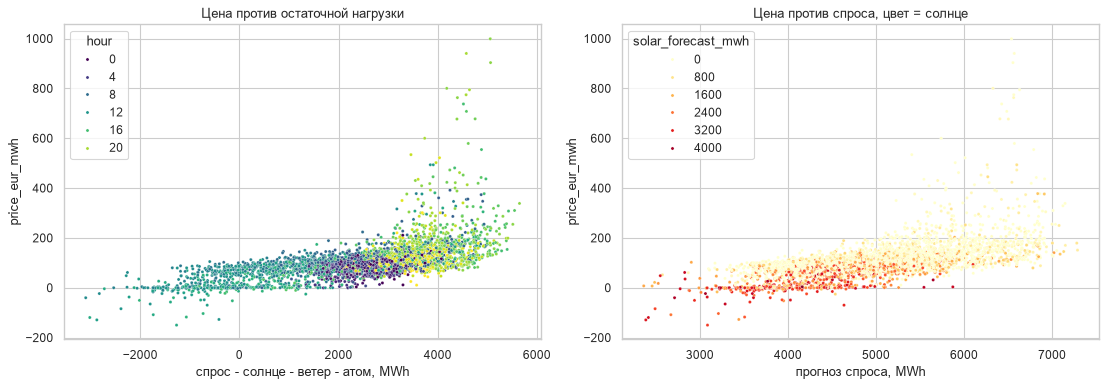

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sample = eda.sample(4000, random_state=0)
sns.scatterplot(data=sample, x="residual_load", y=TARGET, hue="hour", palette="viridis", s=8, ax=axes[0])
axes[0].set(title="Цена против остаточной нагрузки", xlabel="спрос - солнце - ветер - атом, MWh")
sns.scatterplot(data=sample, x="demand_forecast_mwh", y=TARGET, hue="solar_forecast_mwh",
                palette="YlOrRd", s=8, ax=axes[1])
axes[1].set(title="Цена против спроса, цвет = солнце", xlabel="прогноз спроса, MWh")
plt.tight_layout()

Связь цены с остаточной нагрузкой выпуклая, похожа на merit-order кривую: при низкой остаточной нагрузке цена
около нуля, при высокой растёт быстрее линейного. Линейной модели на сырых признаках не хватит: нужны
нелинейные преобразования или деревья. При одном и том же спросе цена заметно ниже, когда солнца много.

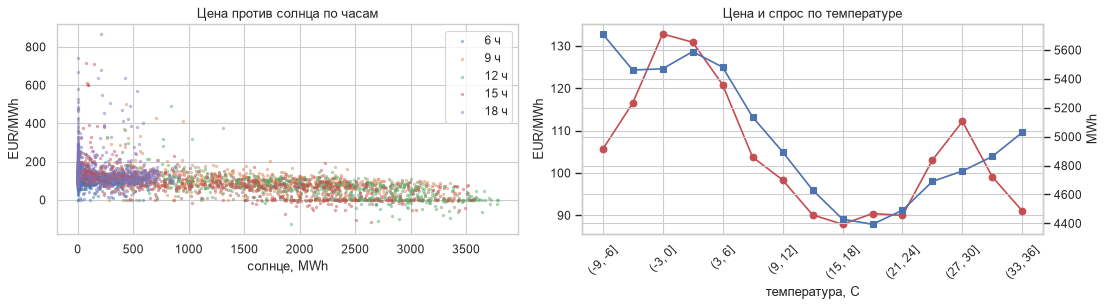

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for h in [6, 9, 12, 15, 18]:
    sub = eda[eda["hour"] == h]
    axes[0].scatter(sub["solar_forecast_mwh"], sub[TARGET], s=4, alpha=0.4, label=f"{h} ч")
axes[0].set(title="Цена против солнца по часам", xlabel="солнце, MWh", ylabel="EUR/MWh")
axes[0].legend()

temp_bin = pd.cut(eda["temperature_forecast_c"], bins=range(-9, 40, 3))
by_temp = eda.groupby(temp_bin, observed=True)[[TARGET, "demand_forecast_mwh"]].mean()
ax2 = axes[1]
by_temp[TARGET].plot(ax=ax2, marker="o", color="C3", label="цена, EUR/MWh")
ax2.set(title="Цена и спрос по температуре", xlabel="температура, C", ylabel="EUR/MWh")
ax2.tick_params(axis="x", rotation=45)
by_temp["demand_forecast_mwh"].plot(ax=ax2.twinx(), marker="s", color="C0", label="спрос, MWh").set_ylabel("MWh")
plt.tight_layout()

Эффект солнца зависит от часа: в полдень корреляция цены с солнцем около -0.6, при больших значениях цена уходит
в ноль и ниже; в 18 ч солнца почти нет и связь исчезает. Модели нужно взаимодействие "час x солнце"
или остаточная нагрузка, которая его уже содержит.

Температура действует через спрос U-образно: дорого и в мороз, и в жару выше 27 C, дешевле всего при 12-20 C.
Как линейный признак температура мало что даст.

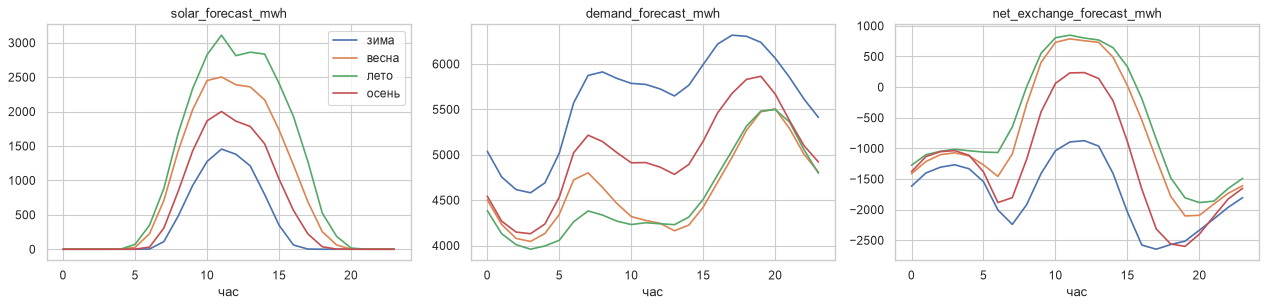

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["solar_forecast_mwh", "demand_forecast_mwh", "net_exchange_forecast_mwh"]):
    for season in ["зима", "весна", "лето", "осень"]:
        eda[eda["season"] == season].groupby("hour")[col].mean().plot(ax=ax, label=season)
    ax.set(title=col, xlabel="час")
axes[0].legend()
plt.tight_layout()

Суточные профили признаков по сезонам: летом солнца втрое больше и светит дольше, спрос выше зимой, импорт
максимален ночью и зимой, а в солнечные летние полдни Венгрия почти выходит в ноль по обмену.

### Атом: остановы блоков Пакша

часов с генерацией ниже 1800: 6290 (36%)
средняя цена при остановах и в норме: 96.9 109.0


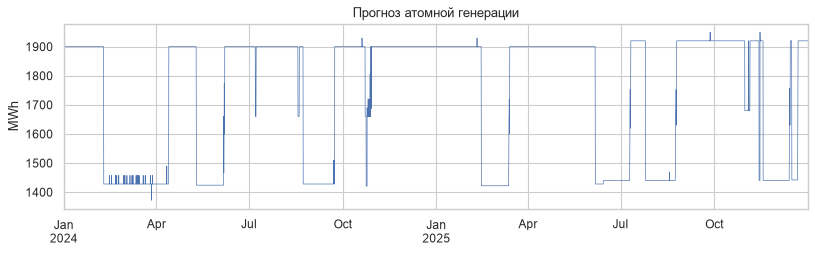

In [24]:
fig, ax = plt.subplots(figsize=(12, 3))
eda["nuclear_forecast_mwh"].plot(ax=ax, lw=0.6, title="Прогноз атомной генерации")
ax.set(xlabel="", ylabel="MWh");

low_nuc = eda["nuclear_forecast_mwh"] < 1800
print(f"часов с генерацией ниже 1800: {low_nuc.sum()} ({low_nuc.mean():.0%})")
print("средняя цена при остановах и в норме:", round(price[low_nuc].mean(), 1), round(price[~low_nuc].mean(), 1))

Нормальный уровень около 1900 MWh, при останове одного блока падает до 1400. Остановов 10-12 в год длиной от
нескольких дней до двух месяцев, это 36% часов. Корреляция с ценой низкая, но режим известен заранее и
входит в остаточную нагрузку.

## 6. Лаги и стационарность

Прогноз на завтра делается сегодня до полудня: цены за сегодня уже известны, за завтра нет.
Поэтому минимальный честный лаг цены 24 ч, а скользящие окна тоже сдвигаем на 24 ч.

In [25]:
lags = pd.DataFrame({
    "lag_24": price.shift(24),
    "lag_48": price.shift(48),
    "lag_168": price.shift(168),
    "roll_mean_24": price.shift(24).rolling(24).mean(),
    "roll_std_24": price.shift(24).rolling(24).std(),
    "roll_mean_168": price.shift(24).rolling(168).mean(),
})
print(lags.corrwith(price).round(3))

for name, s in [("цена", price), ("цена - lag_24", price - lags["lag_24"])]:
    stat, pval = adfuller(s.dropna(), maxlag=48)[:2]
    print(f"ADF {name}: stat = {stat:.2f}, p = {pval:.3g}")

lag_24           0.778
lag_48           0.636
lag_168          0.687
roll_mean_24     0.376
roll_std_24      0.224
roll_mean_168    0.391
dtype: float64


ADF цена: stat = -9.52, p = 3.04e-16


ADF цена - lag_24: stat = -21.98, p = 0


Лаги цены связаны с ней сильнее любого внешнего признака: lag_24 0.78, lag_168 0.69; скользящие средние
заметно слабее (около 0.4), они сглаживают суточный профиль. ADF отвергает единичный корень, формально ряд стационарный, но уровень и дисперсия меняются по сезонам
и годам (лето 2024), поэтому валидировать модель нужно на нескольких периодах, а не на одном случайном сплите.

## 7. Выводы

1. **Данные чистые**: 17 544 часа без пропусков и дыр, переход на летнее время учтён в локальном времени.
   Единственная странность: округлённый прогноз сальдо обмена в апреле-сентябре 2024, уточнить у куратора.
2. **Цена сильно скошена вправо**: медиана 98 EUR/MWh, но хвосты от -210 до 999. Логарифм к ней
   не применить из-за отрицательных значений.
3. **Сезонность трёхуровневая**: суточная (два пика, дневной провал от солнца), недельная (выходные и праздники
   на 30 EUR дешевле, ACF на 168 ч выше, чем на 48 ч), годовая (дорогие зима и июль, дешёвые апрель-май).
   Суточный профиль меняется по сезону.
4. **Выбросы это не шум**: отрицательные цены это солнечные полдни выходных весной и летом, пики это зимние и
   июльские вечера с высоким спросом и импортом. Их надо прогнозировать, а не обрезать.
5. **Главный драйвер остаточная нагрузка** (спрос - солнце - ветер - атом), связь выпуклая. Ветер и атом сами по
   себе малоинформативны, но входят в остаточную нагрузку. Температура действует U-образно через спрос.
6. **Лаги цены сильнее внешних признаков**, но доступны только от 24 ч (утечка иначе).

Что из этого следует для этапа моделей: цена зависит от календаря (час, день недели, праздники, сезон),
нелинейно от остаточной нагрузки и от собственных лагов не ближе 24 ч. Качество прогноза нужно смотреть
отдельно на хвостах и проверять на разных периодах, а не на одном случайном разбиении.